In [2]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv("../data/hotel_bookings.csv")

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [8]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import joblib

In [10]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [11]:
df['children'].fillna(0,inplace=True)

C:\Users\aeccs\AppData\Local\Temp\ipykernel_5312\3709283096.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['children'].fillna(0,inplace=True)


0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
119385    0.0
119386    0.0
119387    0.0
119388    0.0
119389    0.0
Name: children, Length: 119390, dtype: float64

In [12]:
df['children'].isnull().sum()

np.int64(4)

In [13]:
df['children'].value_counts()

children
0.0     110796
1.0       4861
2.0       3652
3.0         76
10.0         1
Name: count, dtype: int64

In [14]:
is_canceled=df['is_canceled'].value_counts()
cancelled_count=is_canceled.get(1,0)
total_count=len(df)
print("percentage of canceled bookings: ",(cancelled_count/total_count)*100)

percentage of canceled bookings:  37.041628277075134


In [15]:
cancellation_types=df['reservation_status'].value_counts(normalize=True)*100
print(cancellation_types)

reservation_status
Check-Out    62.958372
Canceled     36.030656
No-Show       1.010972
Name: proportion, dtype: float64


Text(0.5, 1.0, 'reservation status vs Cancellation Types')

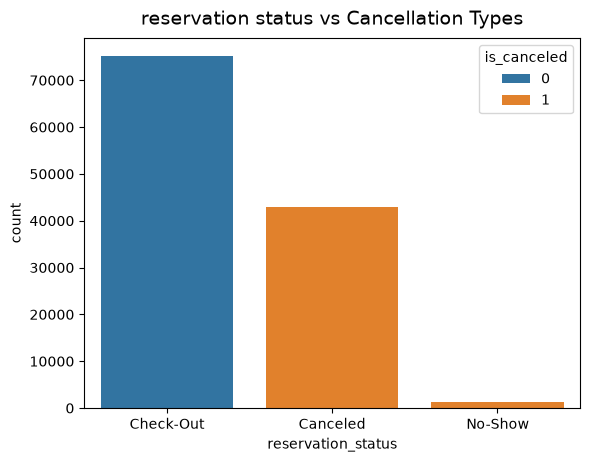

In [16]:
sns.countplot(x='reservation_status',data=df,hue='is_canceled')
plt.title("reservation status vs Cancellation Types",fontsize=14,pad=10)

([<matplotlib.axis.XTick at 0x17689529a90>,
 [Text(0, 0, 'Not Canceled'), Text(1, 0, 'Canceled')])

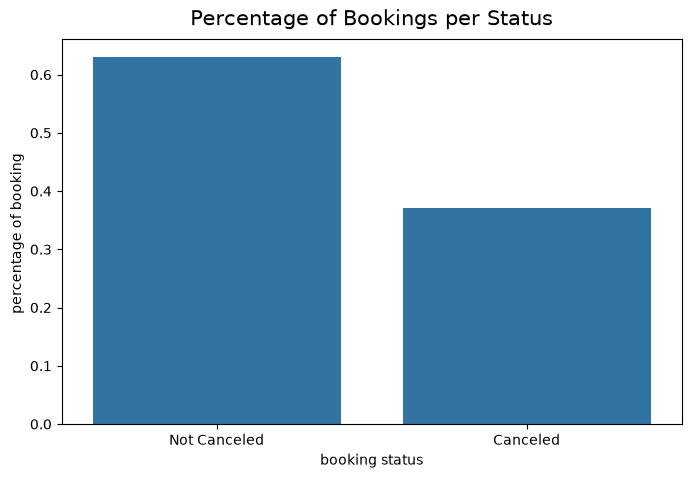

In [17]:
#visualising the percentage of cancelled vs not cancelled bookings
plt.figure(figsize=(8,5))
plt.title("Percentage of Bookings per Status", fontsize = 15, pad = 10)
sns.barplot(x=df['is_canceled'].unique(), y=df['is_canceled'].value_counts(normalize=True))
plt.xlabel("booking status")
plt.ylabel("percentage of booking ")
plt.xticks(ticks=[0,1],labels=['Not Canceled','Canceled'])



In [18]:
corr = df.corr(method='pearson', numeric_only=True)['is_canceled'][1:]
corr.sort_values(ascending=False)

lead_time                         0.293123
previous_cancellations            0.110133
adults                            0.060017
days_in_waiting_list              0.054186
adr                               0.047557
stays_in_week_nights              0.024765
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
children                          0.005048
stays_in_weekend_nights          -0.001791
arrival_date_day_of_month        -0.006130
company                          -0.020642
babies                           -0.032491
previous_bookings_not_canceled   -0.057358
agent                            -0.083114
is_repeated_guest                -0.084793
booking_changes                  -0.144381
required_car_parking_spaces      -0.195498
total_of_special_requests        -0.234658
Name: is_canceled, dtype: float64

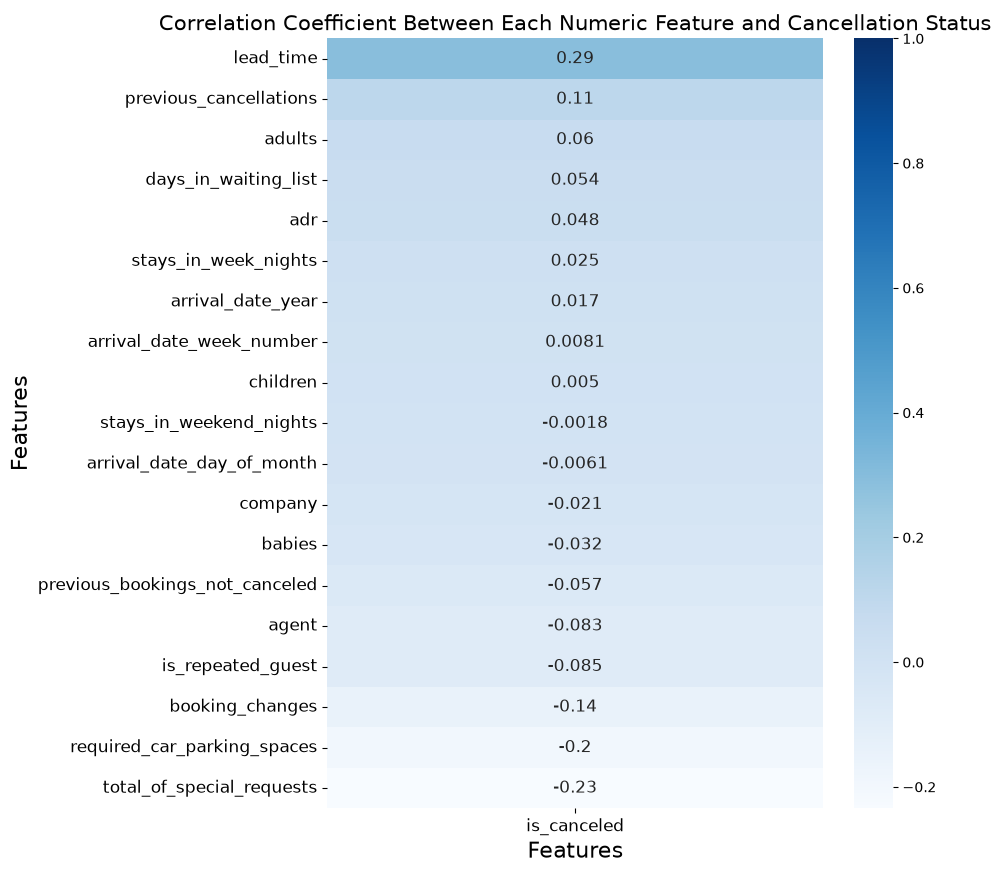

In [19]:
#vusalising the correlation coeeficients between features and cancellations
fig = plt.figure(figsize=(8,10))
ax = sns.heatmap(df.corr(numeric_only=True)[['is_canceled']].sort_values('is_canceled', ascending=False), annot = True, annot_kws = {"size":12}, cmap='Blues')
ax.set_title('Correlation Coefficient Between Each Numeric Feature and Cancellation Status', fontsize=15)
ax.set_xlabel('Features', fontsize = 16)
ax.set_ylabel('Features', fontsize = 16)
ax.tick_params(axis = "both", labelsize = 12);
y_min, y_max = ax.get_ylim()
ax.set_ylim(top=y_max+1);

Cancellations in resort hotel=  0.27763354967548676
Cancellations in city hotel=  0.41726963317786464


Text(0.5, 1.0, 'Total count of bookings and cancellations per hotel')

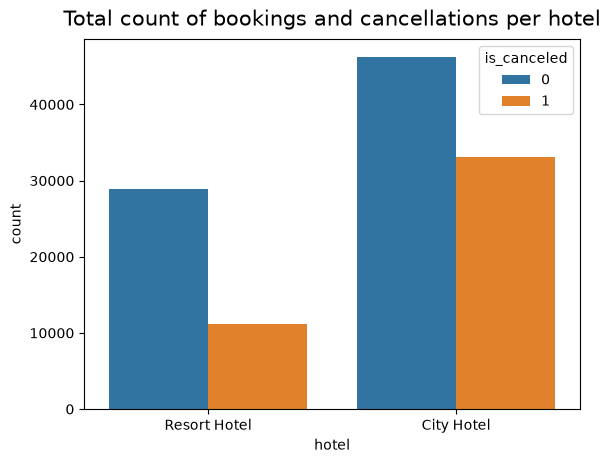

In [20]:
sns.countplot(data=df,x='hotel',hue='is_canceled')

resort_canceled = df[(df['hotel'] == 'Resort Hotel') & (df['is_canceled'] == 1)]
city_canceled = df[(df['hotel'] == 'City Hotel') & (df['is_canceled'] == 1)]

print('Cancellations in resort hotel= ', (len(resort_canceled)) / (len(df[df['hotel'] == 'Resort Hotel'])))
print('Cancellations in city hotel= ', (len(city_canceled)) / (len(df[df['hotel'] == 'City Hotel'])))

plt.title("Total count of bookings and cancellations per hotel", fontsize = 15, pad = 10)

In [21]:
#our assumption that city hotels have higher cancellation rates than resort hotels is valid 

In [22]:
print(len(df[(df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)]))

715


In [23]:
#715 bookings don't have both weekday or weekend nights which could be an error in the data as this is not possible in real life scenario. Therefore these rows can be eliminated from the dataset.

In [24]:
((len(df.loc[(df['children'] != 0) | (df['babies'] != 0)]))/(len(df))) * 100

7.819750397855767

In [25]:
#The number of customers having children or babies or both are only 8.00% (7.81% precisely) of the total population. Therefore this information can be ignored as it will not play a significant role in deciding whether to cancel the booking or not.

Cancellations in resort hotel=  0.27763354967548676
Cancellations in city hotel=  0.41726963317786464


Text(0.5, 1.0, 'Total count of bookings and cancellations per hotel')

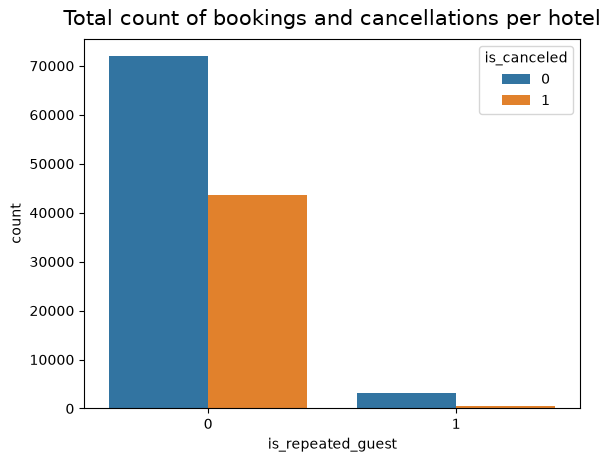

In [26]:
sns.countplot(data=df,x='is_repeated_guest',hue='is_canceled')

new_guest=df[(df['is_repeated_guest']==0) & (df['is_canceled']==1)]
city_canceled = df[(df['hotel'] == 'City Hotel') & (df['is_canceled'] == 1)]

print('Cancellations in resort hotel= ', (len(resort_canceled)) / (len(df[df['hotel'] == 'Resort Hotel'])))
print('Cancellations in city hotel= ', (len(city_canceled)) / (len(df[df['hotel'] == 'City Hotel'])))

plt.title("Total count of bookings and cancellations per hotel", fontsize = 15, pad = 10)

In [27]:
#As seen in the correlation table, the above graph is the evidence that maximum customers are new comers and they are less likely to cancel their current booking. Old guests are less likely to cancel the booking (14%).

Text(0.5, 1.0, 'total count of previous cancellations')

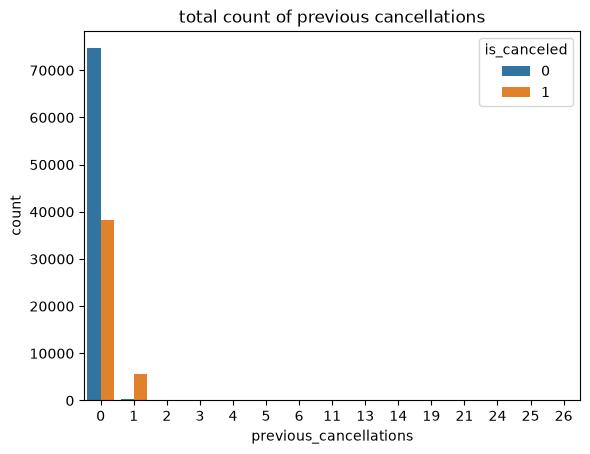

In [28]:
sns.countplot(data=df,x='previous_cancellations',hue='is_canceled')
plt.title("total count of previous cancellations")

In [29]:
#Maximum customers have 0 previous cancellations. They are less likely to cancel the current booking. However, customers who have cancelled once earlier are more likely to cancel the current booking. This also matches with the positive correlation between previous_cancellations and is_cancelled

In [30]:
temp = df.loc[df['reserved_room_type'] != df['assigned_room_type']]
temp['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    94.623584
1     5.376416
Name: proportion, dtype: float64

In [31]:
#there more cancellations when assigned room type is different from reserved room type is not valid. 

Text(0.5, 1.0, 'Booking Changes VS Cancellations')

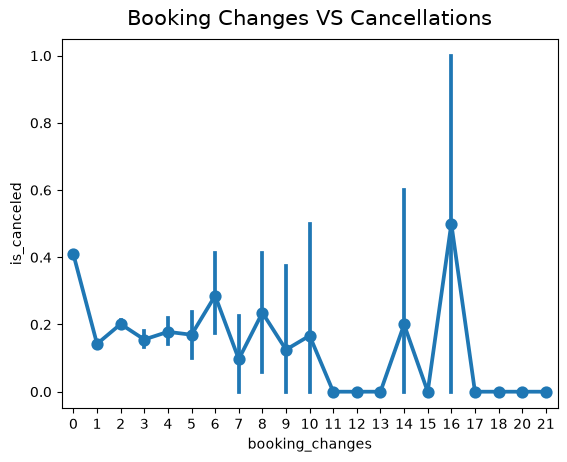

In [32]:
#booking changes vs cancellations
sns.pointplot(data = df, x = 'booking_changes', y = 'is_canceled')
plt.title("Booking Changes VS Cancellations", fontsize = 15, pad = 10)

Text(0.5, 1.0, 'cancellation vs depsoit type ')

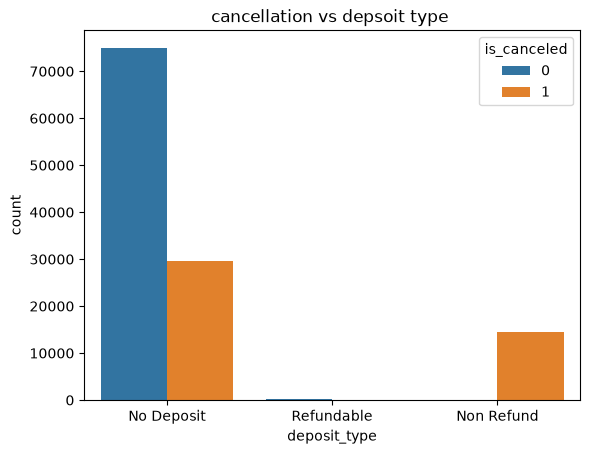

In [33]:
sns.countplot(x='deposit_type',hue='is_canceled',data=df)
plt.title("cancellation vs depsoit type ")

In [34]:
#bookings that are non refundable are cancelled 

Text(0.5, 1.0, 'Days in waiting VS cancellations')

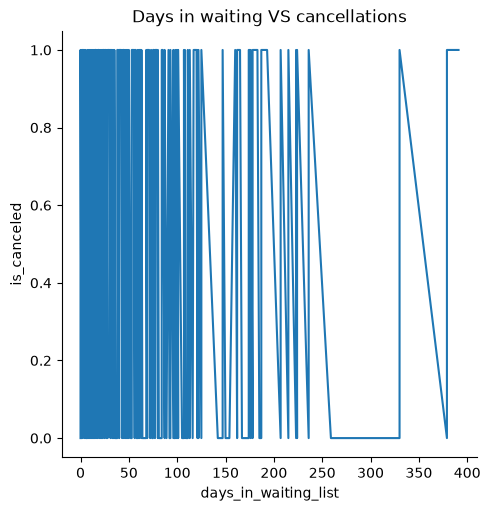

In [35]:
#days in waiting vs cancelations
sns.relplot(data = df, x ='days_in_waiting_list', y = 'is_canceled', kind = 'line', estimator = None)
plt.title("Days in waiting VS cancellations")


In [36]:
#No relation can be established between days_in_waiting_list and is_canceled. Therefore, we will take this feature for further analysis.

In [37]:
year_cancellations = df.groupby(['arrival_date_year'])['is_canceled'].sum()
year_cancellations

arrival_date_year
2015     8142
2016    20337
2017    15745
Name: is_canceled, dtype: int64

Text(0.5, 1.0, 'Total number of bookings per year')

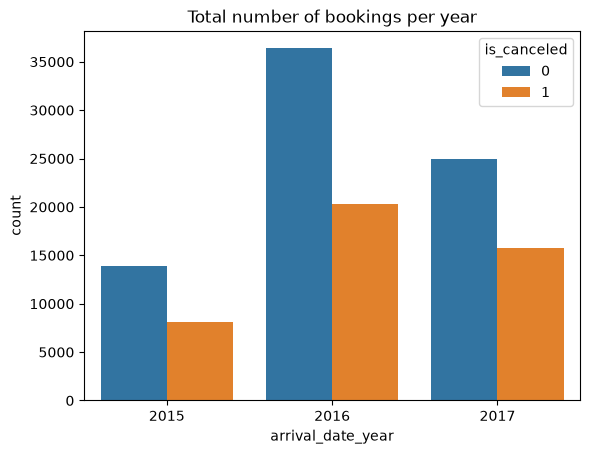

In [38]:
sns.countplot(data = df, x = 'arrival_date_year', hue = 'is_canceled')
plt.title("Total number of bookings per year")

In [39]:
month_cancellations=df.groupby(['arrival_date_month'])['is_canceled'].sum()
month_cancellations

arrival_date_month
April        4524
August       5239
December     2371
February     2696
January      1807
July         4742
June         4535
March        3149
May          4677
November     2122
October      4246
September    4116
Name: is_canceled, dtype: int64

Text(0.5, 1.0, 'monthly cancellations')

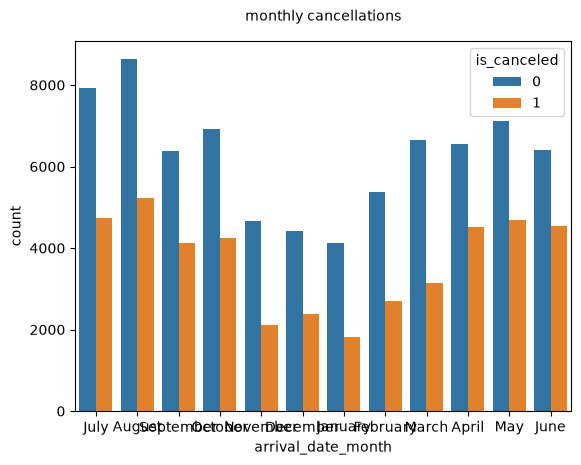

In [41]:
sns.countplot(data=df,x='arrival_date_month',hue='is_canceled')
plt.title("monthly cancellations",fontsize=10,pad=15)

In [46]:
year_count= df.groupby(['arrival_date_year','is_canceled']).size().to_frame(name='count')
year_perct=year_count.groupby(level = 0).apply(lambda x:100 * x / (x.sum()))
print(year_perct)
month_count = df.groupby(['arrival_date_month', 'is_canceled']).size().to_frame(name = 'count')
month_perct = month_count.groupby(level = 0).apply(lambda x:100 * x / (x.sum()))
print(month_perct)

                                                     count
arrival_date_year arrival_date_year is_canceled           
2015              2015              0            62.984179
                                    1            37.015821
2016              2016              0            64.136703
                                    1            35.863297
2017              2017              0            61.302136
                                    1            38.697864
                                                       count
arrival_date_month arrival_date_month is_canceled           
April              April              0            59.202814
                                      1            40.797186
August             August             0            62.246883
                                      1            37.753117
December           December           0            65.029499
                                      1            34.970501
February           February           0 

In [47]:
#percentage of cancellations is higher in 2015 and 2017 despite of the hogher number of booking in 2016.
#April  and june has the highest cancellations overall 

Text(0.5, 1.0, 'Total cancellations acorss market segment')

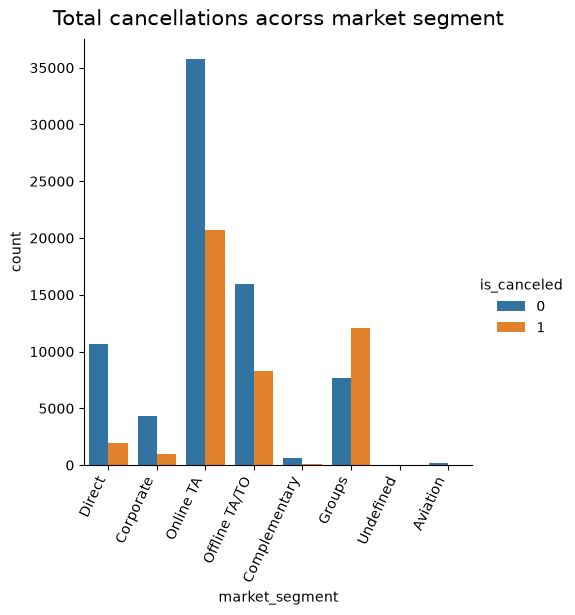

In [48]:
chart = sns.catplot(data = df, x = 'market_segment', kind = 'count', hue = 'is_canceled')
chart.set_xticklabels(rotation = 65, horizontalalignment = 'right')
plt.title("Total cancellations acorss market segment", fontsize = 15, pad = 10)

Text(0.5, 1.0, 'Distribution of cancellations in various channels')

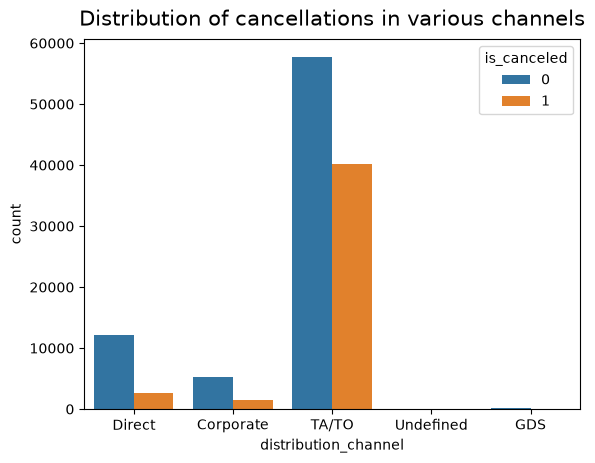

In [49]:
sns.countplot(data = df, x = 'distribution_channel', hue = 'is_canceled')
plt.title("Distribution of cancellations in various channels", fontsize = 15, pad = 10)

customer_type
Transient          75.059050
Transient-Party    21.043638
Contract            3.414021
Group               0.483290
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Average Number of cancellations in each category')

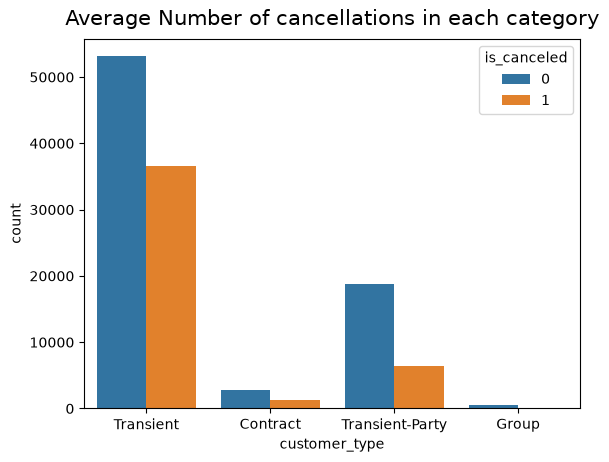

In [50]:
print(df['customer_type'].value_counts(normalize = True) * 100)
sns.countplot(data = df, x = 'customer_type', hue = 'is_canceled')
plt.title("Average Number of cancellations in each category", fontsize = 15, pad = 10)

In [51]:
#
#75% bookings occur in Transient category of customers. It also sees the highest cancellation among all the categories.

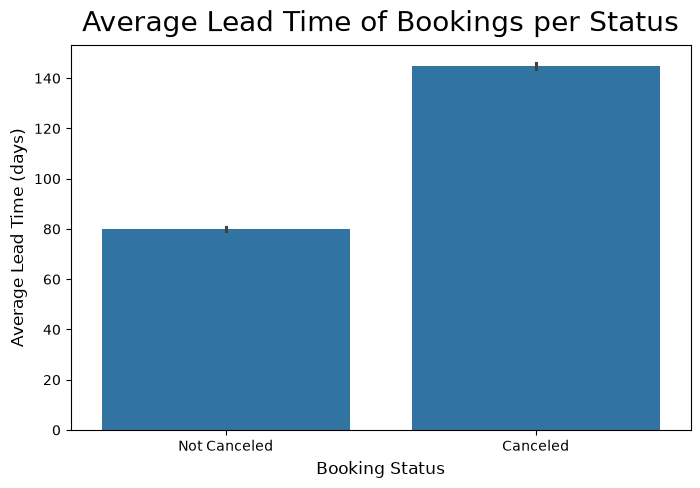

In [53]:
# Visualizing the average lead time for canceled and not canceled bookings:
plt.figure(figsize=(8,5)) 
plt.title("Average Lead Time of Bookings per Status", fontsize = 20, pad = 10)
sns.barplot(x=df['is_canceled'], y=df['lead_time'])
plt.xlabel("Booking Status", fontsize = 12, labelpad = 5)
plt.ylabel("Average Lead Time (days)", fontsize = 12, labelpad = 5)
plt.xticks(ticks=[0, 1], labels=['Not Canceled', 'Canceled']);


In [54]:
#
#Maximum cancellations occur if the booking is made 60-70 days before the check-in date. Longer the lead_time, lower is the cancellation.

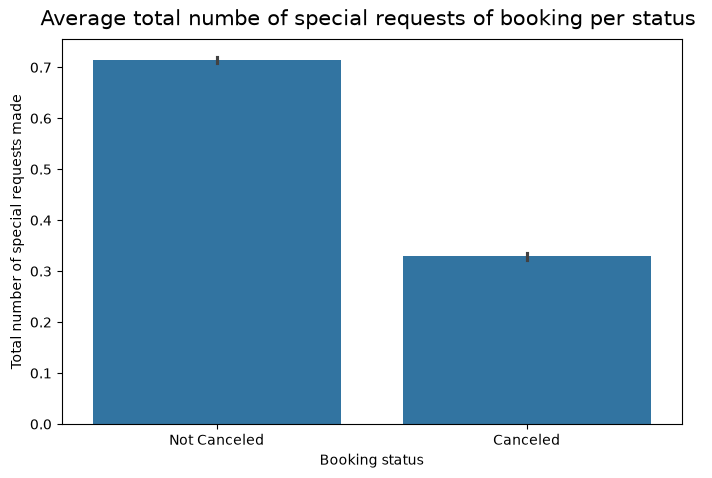

In [57]:
#visualising total numbers of special request 
plt.figure(figsize=(8,5))
plt.title("Average total numbe of special requests of booking per status ",fontsize=15,pad=10)
sns.barplot(x=df['is_canceled'],y=df['total_of_special_requests'])
plt.xlabel("Booking status")
plt.ylabel("Total number of special requests made")
plt.xticks(ticks=[0, 1], labels=['Not Canceled', 'Canceled']);

In [58]:
#Customers who cancel their bookings make on average fewer special requests.

([<matplotlib.axis.XTick at 0x17695255e50>,
 [Text(0, 0, 'Not Canceled'), Text(1, 0, 'Canceled')])

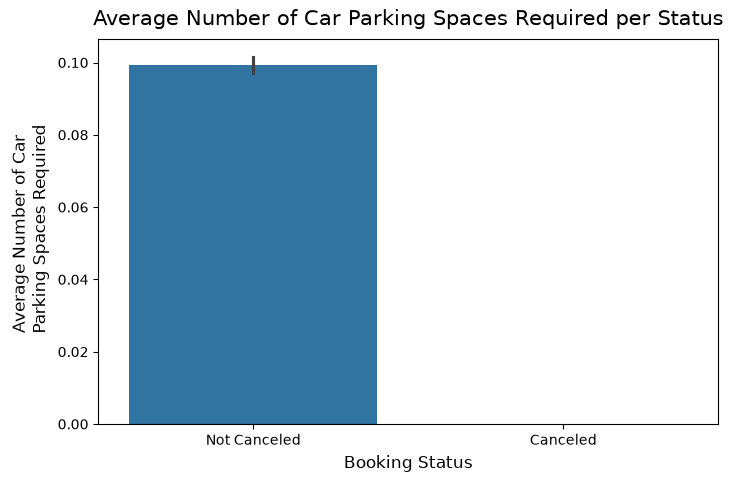

In [59]:
#visualising the total number of requested parking spaces for cancelled and not cancelled booking 
plt.figure(figsize=(8,5)) 
plt.title("Average Number of Car Parking Spaces Required per Status", fontsize = 15, pad = 10)
sns.barplot(x=df['is_canceled'], y=df['required_car_parking_spaces'])
plt.xlabel("Booking Status", fontsize = 12, labelpad = 5)
plt.ylabel("Average Number of Car \n Parking Spaces Required", fontsize = 12, labelpad = 5)
plt.xticks(ticks=[0, 1], labels=['Not Canceled', 'Canceled'])

In [60]:
# On average, customers who do not cancel their bookings tend to require more parking spaces

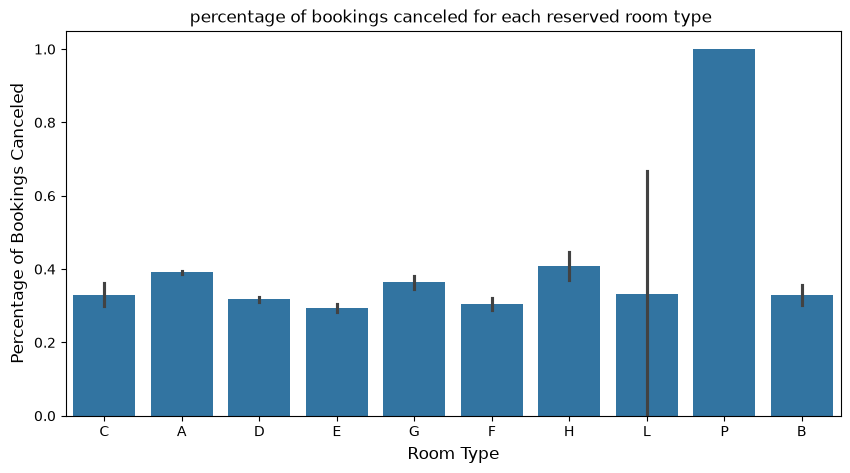

In [62]:
#visuaising percentage of booking canceled for each type of room 
plt.figure(figsize=(10,5))
plt.title("percentage of bookings canceled for each reserved room type ")
sns.barplot(x=df['reserved_room_type'],y=df['is_canceled'])
plt.xlabel("Room Type", fontsize = 12, labelpad = 5)
plt.ylabel("Percentage of Bookings Canceled", fontsize = 12, labelpad = 5);

In [63]:
#Customers who reserved room type P have the highest percentage booking cancellation with 100% of bookings canceled. As the dataset did not provide the actual room designations for anonymity purposes, it is hard to interpret why bookings of room type P are canceled more often.

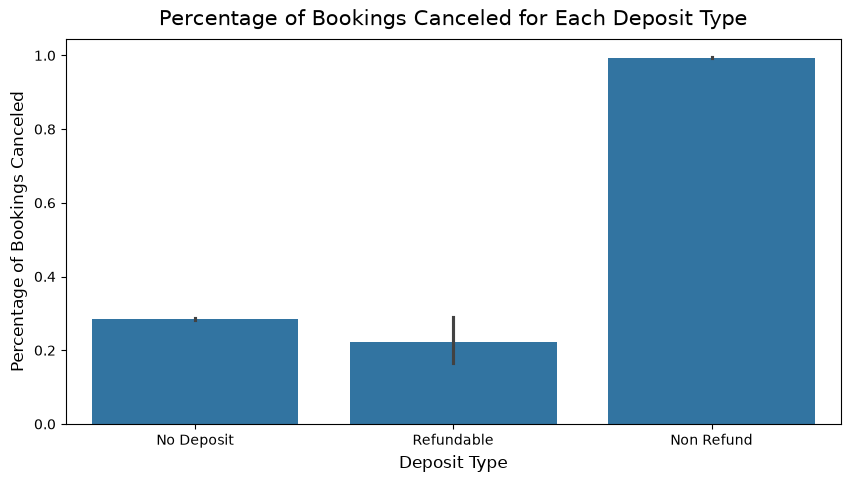

In [64]:
# Visualizing percentage of bookings canceled for each deposit type:
plt.figure(figsize=(10,5)) 
plt.title("Percentage of Bookings Canceled for Each Deposit Type", fontsize = 15, pad = 10)
sns.barplot(x=df['deposit_type'], y=df['is_canceled'])
plt.xlabel("Deposit Type", fontsize = 12, labelpad = 5)
plt.ylabel("Percentage of Bookings Canceled", fontsize = 12, labelpad = 5);

In [65]:
#Surprisingly, customers who pay a non-refundable deposit have a much higher percentage of canceled reservations.

In [66]:
df['reservation_status'].unique()

<StringArray>
['Check-Out', 'Canceled', 'No-Show']
Length: 3, dtype: str

c:\Users\aeccs\OneDrive\Desktop\hotel-booking-predictor\.venv\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


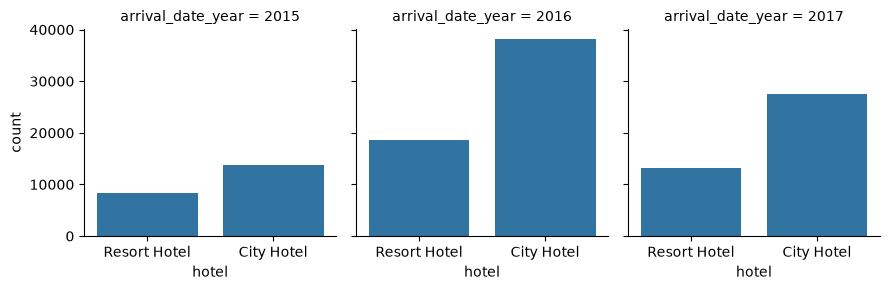

In [67]:
grid=sns.FacetGrid(df,col='arrival_date_year')
grid.map(sns.countplot,'hotel')

In [68]:
#
#In all three years city hotels saw more bookings than resort hotels.

c:\Users\aeccs\OneDrive\Desktop\hotel-booking-predictor\.venv\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


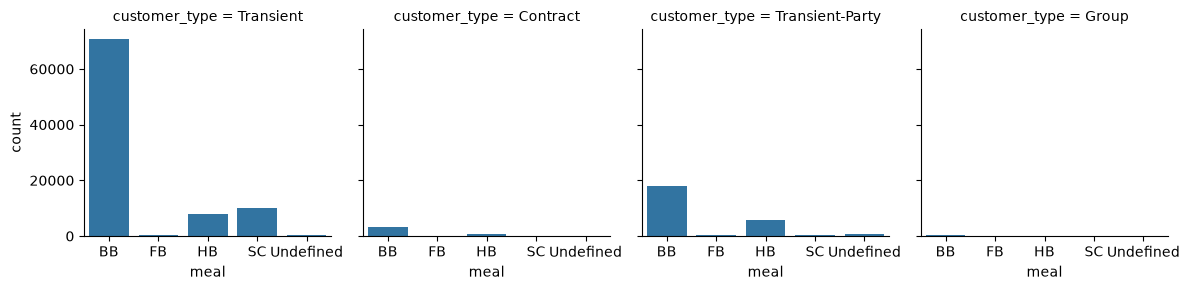

In [69]:
df['meal'].nunique(),df['customer_type'].nunique()
grid=sns.FacetGrid(df,col='customer_type')
grid.map(sns.countplot,'meal')

In [70]:
##Mainly all kinds of customers prefer BB type meals.

In [71]:
df.pivot_table(columns='hotel', values='country', aggfunc=lambda x:x.mode())

C:\Users\aeccs\AppData\Local\Temp\ipykernel_5312\2513293350.py:1: Pandas4Warning: Converting a Series or array of length 1 into a scalar is deprecated and will be removed in a future version. If you wish to preserve the current behavior, have ``func`` return scalars.
  df.pivot_table(columns='hotel', values='country', aggfunc=lambda x:x.mode())


hotel,City Hotel,Resort Hotel
country,PRT,PRT


In [73]:
#people from country code 'prt' made the most number of bookings in both type of hotels

Text(0.5, 1.0, 'Reversed room type booked VS Hotel')

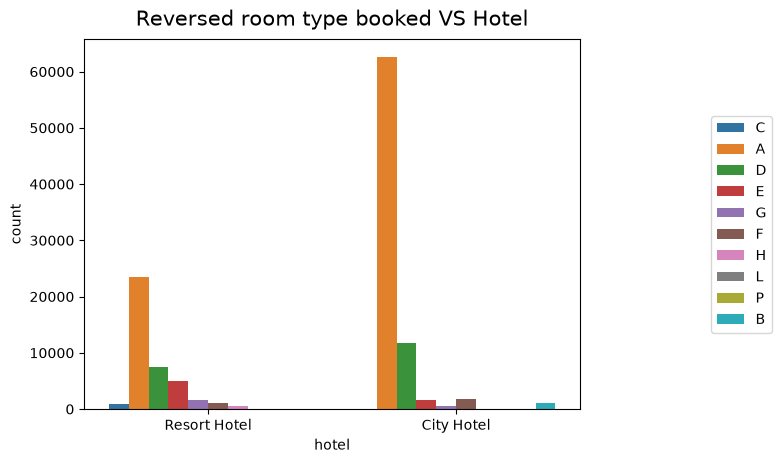

In [74]:
g = sns.countplot(data = df, x = 'hotel', hue = 'reserved_room_type')
g.legend(loc = 'center left', bbox_to_anchor = (1.25, 0.5), ncol = 1)
plt.title("Reversed room type booked VS Hotel", fontsize = 15, pad = 10)

In [75]:
#Resort hotels room preference : A, D, E
#City hotels room preference : A, D, F

In [77]:
print("TABLE 1")
print(df.groupby(['hotel', 'customer_type']).size())

TABLE 1
hotel         customer_type  
City Hotel    Contract            2300
              Group                293
              Transient          59404
              Transient-Party    17333
Resort Hotel  Contract            1776
              Group                284
              Transient          30209
              Transient-Party     7791
dtype: int64


In [78]:
print(df.groupby(['customer_type', 'deposit_type']).size())

customer_type    deposit_type
Contract         No Deposit       3530
                 Non Refund        544
                 Refundable          2
Group            No Deposit        569
                 Refundable          8
Transient        No Deposit      76684
                 Non Refund      12909
                 Refundable         20
Transient-Party  No Deposit      23858
                 Non Refund       1134
                 Refundable        132
dtype: int64


In [79]:
#Each category of customers book hotels without deposit. Surprisingly, between refundable and non-refundable type, higher number of people book hotels that are non-refundable.

In [80]:
print(df.groupby(['customer_type', 'market_segment']).size())

customer_type    market_segment
Contract         Complementary         2
                 Corporate            22
                 Direct               14
                 Groups              735
                 Offline TA/TO      1817
                 Online TA          1486
Group            Aviation              2
                 Complementary         6
                 Corporate            29
                 Direct              134
                 Groups               16
                 Offline TA/TO       211
                 Online TA           179
Transient        Aviation            218
                 Complementary       703
                 Corporate          3576
                 Direct            11336
                 Groups             8427
                 Offline TA/TO     14054
                 Online TA         51299
Transient-Party  Aviation             17
                 Complementary        32
                 Corporate          1668
                 Direct  

In [81]:
print(df.groupby(['hotel', 'distribution_channel']).size())

hotel         distribution_channel
City Hotel    Corporate                3408
              Direct                   6780
              GDS                       193
              TA/TO                   68945
              Undefined                   4
Resort Hotel  Corporate                3269
              Direct                   7865
              TA/TO                   28925
              Undefined                   1
dtype: int64


In [82]:
print(df.groupby(['hotel', 'market_segment']).size())

hotel         market_segment
City Hotel    Aviation            237
              Complementary       542
              Corporate          2986
              Direct             6093
              Groups            13975
              Offline TA/TO     16747
              Online TA         38748
              Undefined             2
Resort Hotel  Complementary       201
              Corporate          2309
              Direct             6513
              Groups             5836
              Offline TA/TO      7472
              Online TA         17729
dtype: int64


In [84]:
df.pivot_table(columns = 'hotel', values = ['stays_in_weekend_nights', 'stays_in_week_nights'], aggfunc = lambda x:x.sum())

hotel,City Hotel,Resort Hotel
stays_in_week_nights,173174,125337
stays_in_weekend_nights,63082,47664


In [85]:
df.pivot_table(columns = 'hotel', values = 'total_of_special_requests', aggfunc = lambda x:x.sum())

hotel,City Hotel,Resort Hotel
total_of_special_requests,43387,24828


Text(0.5, 1.0, 'Days in waiting VS Hotel')

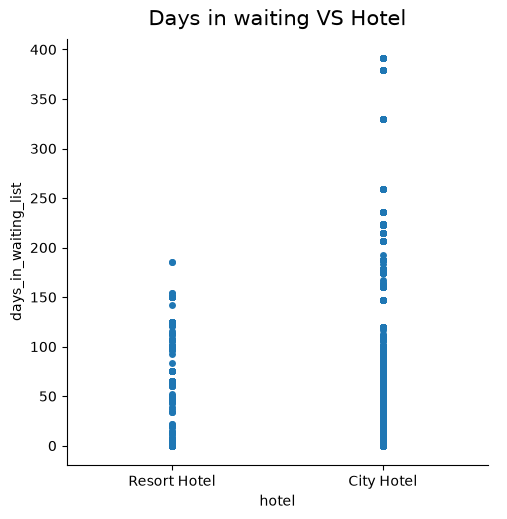

In [86]:
sns.catplot(data = df, x = 'hotel', y = 'days_in_waiting_list', jitter = False)
plt.title("Days in waiting VS Hotel", fontsize = 15, pad = 10)

In [87]:
#as it is seen that the city hotels have a hoigher waiting period in days than the resort hotel and hence this signifies the demandof city hotel 

In [88]:
df['country'].value_counts(normalize = True) * 10

country
PRT    4.086559
GBR    1.020084
FRA    0.875931
ESP    0.720593
DEU    0.612858
         ...   
NCL    0.000084
KIR    0.000084
SDN    0.000084
ATF    0.000084
SLE    0.000084
Name: proportion, Length: 177, dtype: float64

c:\Users\aeccs\OneDrive\Desktop\hotel-booking-predictor\.venv\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


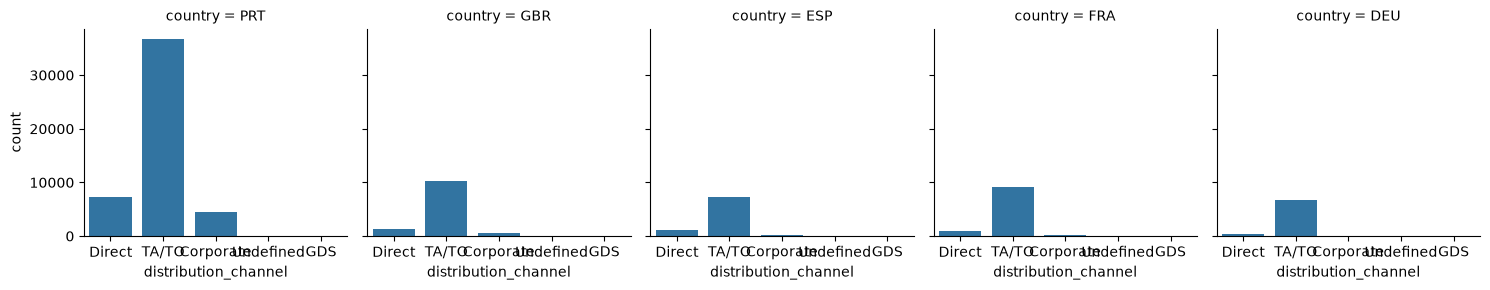

In [92]:
temp = df.loc[(df['country'] == 'PRT') | (df['country'] == 'GBR') | (df['country'] == 'FRA') | (df['country'] == 'ESP') | (df['country'] == 'DEU')]
grid = sns.FacetGrid(temp, col = 'country')
grid.map(sns.countplot, 'distribution_channel')

In [93]:
# 2. Select key predictive features to keep things simple and efficient
features = [
    'hotel', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'is_repeated_guest', 
    'previous_cancellations', 'booking_changes', 'adr', 'required_car_parking_spaces',
    'total_of_special_requests', 'market_segment', 'customer_type'
]

target = 'is_canceled'

df_model = df[features + [target]].copy()

# 3. Handle missing values
df_model['children'] = df_model['children'].fillna(0)

# 4. Encode categorical text columns into numbers using LabelEncoder
categorical_cols = ['hotel', 'market_segment', 'customer_type']
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))
    encoders[col] = le  # Save encoders if needed later

# 5. Split data into Features (X) and Target (y)
X = df_model[features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Train the Random Forest Model
print("Training the model...")
model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15)
model.fit(X_train, y_train)

# 7. Evaluate model accuracy
accuracy = model.score(X_test, y_test)

# 8. Save the trained model and features list using joblib
joblib.dump(model, 'hotel_model.pkl')
joblib.dump(features, 'model_features.pkl')
print("Model saved successfully as hotel_model.pkl!")

Training the model...
Model saved successfully as hotel_model.pkl!


In [94]:
print(accuracy)

0.8270793198760366
